# 06 · La pregunta: condición de llegada al Skinpass y su evidencia

Declara la **definición operativa de "mala condición de llegada"** (tres criterios
físicos, `src/condicion.py`), mide su prevalencia y muestra la evidencia de viabilidad
de la pregunta de investigación: la condición varía entre productos (9–50 %) y, dentro
de la especificación, el **programa de laminación** explica más que el producto.
Genera la figura 6 y el diagrama causal (Componente 4).

In [1]:
import sys
sys.path.insert(0, "..")  # para importar src/

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.poblacion import preparar, poblacion
from src.condicion import definir_condicion, umbrales_corona, UMBRAL_CUNA_PCT
from src.estadistica import descomposicion_anidada, linea_base_permutacion, wilson
from src.config import TABLAS_DIR
from src.diagramas import diagrama_causal
from src.visualizacion import estilo, guardar, AZUL, NARANJA, VERDE, GRIS

df, d = preparar()
p = poblacion(df)
estilo()

## 1. Definición operativa (declarada en src/condicion.py) y umbrales

In [3]:
u = umbrales_corona(p)
print(f"Umbral C1 (cuña): |cuña| > {UMBRAL_CUNA_PCT} % del espesor")
print("Umbral C2 (corona relativa, p90 por rango de espesor):")
print(u.round(2).to_string())
TABLAS_DIR.mkdir(parents=True, exist_ok=True)
u.round(3).to_csv(TABLAS_DIR / "umbrales_corona.csv")

q = definir_condicion(p)

Umbral C1 (cuña): |cuña| > 1.0 % del espesor
Umbral C2 (corona relativa, p90 por rango de espesor):
rango_espesor
≤1.5     5.58
1.5–2    4.54
2–2.5    3.78
2.5–3    2.96
3–4      2.84
4–6      2.86
>6       1.39


## 2. Prevalencia de cada criterio y del conjunto

In [4]:
def tasa(col):
    return q[col].eq(True).sum() / q[col].notna().sum()

prev = {
    "C1 · cuña > 1 % espesor": tasa("c1_cuna"),
    "C2 · corona relativa alta": tasa("c2_corona"),
    "C3 · T. enrollado fuera de tolerancia": tasa("c3_temp"),
    "Mala condición (alguno)": tasa("mala_condicion"),
}
print("\nPrevalencia en la población (47,588 rollos):")
for k, v in prev.items():
    print(f"  {k}: {100 * v:.1f} %")
print(f"  Rollos con algún criterio sin dato: {100 * q['sin_dato'].mean():.1f} %")

solapa = q[["c1_cuna", "c2_corona", "c3_temp"]].eq(True).sum(axis=1)
print("Criterios cumplidos por rollo:", (solapa.value_counts(normalize=True).sort_index() * 100)
      .round(1).to_dict())


Prevalencia en la población (47,588 rollos):
  C1 · cuña > 1 % espesor: 20.9 %
  C2 · corona relativa alta: 10.0 %
  C3 · T. enrollado fuera de tolerancia: 2.4 %
  Mala condición (alguno): 27.0 %
  Rollos con algún criterio sin dato: 2.5 %
Criterios cumplidos por rollo: {0: 73.0, 1: 21.7, 2: 5.1, 3: 0.2}


## 3. ¿La condición varía entre productos o dentro de ellos? (viabilidad de la pregunta)

In [5]:
y = q["mala_condicion"].eq(True).astype(float).where(~q["mala_condicion"].isna())
q["_y"] = y
print(f"\nPor tipo de material: "
      f"{(q.groupby('tipo_material', observed=True)['_y'].mean() * 100).round(1).to_dict()}")

niveles = ["tipo_material", "norma_grado", "dim", "Programa"]
desc = descomposicion_anidada(q, "_y", niveles)
nulo = linea_base_permutacion(q, "_y", niveles, n_perm=10)
print("\nDescomposición anidada de 'mala condición' (fracción de la variación):")
print((desc.drop("n") * 100).round(1).to_string())
print(f"Línea base por azar del nivel 'Programa': media {100 * nulo['media nula']:.1f} %, "
      f"p95 {100 * nulo['p95 nula']:.1f} %")

# Entre productos con soporte: rango de prevalencias (versión modesta)
n_prod = q.groupby("norma_grado", observed=True)["_y"].agg(["mean", "count"])
grandes = n_prod[n_prod["count"] >= 500].sort_values("mean")
print(f"\nProductos con ≥500 rollos: {len(grandes)}; % mala condición de "
      f"{100 * grandes['mean'].min():.0f} % a {100 * grandes['mean'].max():.0f} %")


Por tipo de material: {'CALIENTE': 31.5, 'DECAPADO': 24.4}



Descomposición anidada de 'mala condición' (fracción de la variación):
tipo_material                           0.6
norma_grado                             8.5
dim                                    15.9
Programa                               50.8
rollo (dentro de la celda más fina)    24.2
Línea base por azar del nivel 'Programa': media 27.1 %, p95 27.3 %

Productos con ≥500 rollos: 29; % mala condición de 9 % a 50 %


## 4. Figura 6: prevalencia por criterio + descomposición contra el azar

/Users/santobenitez/Documents/desarrollo_aplicaciones_avanzadas/Reto-Ternium/outputs/figuras/fig6_condicion_llegada.png


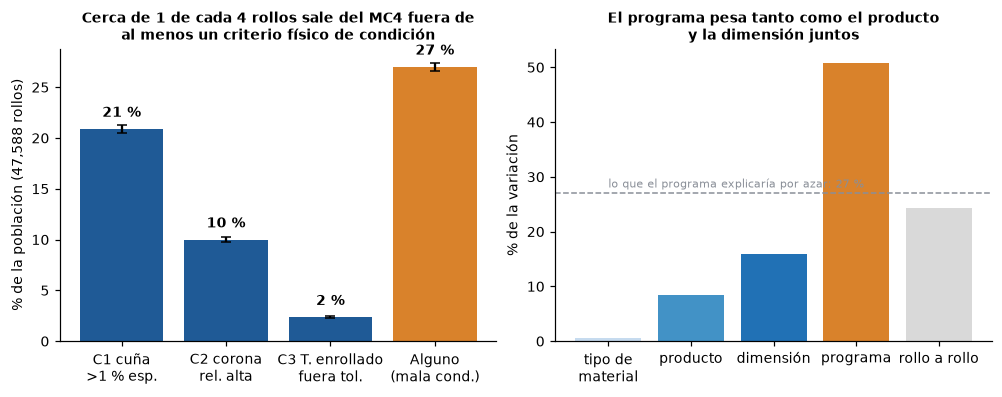

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
nombres = ["C1 cuña\n>1 % esp.", "C2 corona\nrel. alta", "C3 T. enrollado\nfuera tol.", "Alguno\n(mala cond.)"]
vals = [100 * v for v in prev.values()]
ic = [wilson(int(q[c].eq(True).sum()), int(q[c].notna().sum()))
      for c in ["c1_cuna", "c2_corona", "c3_temp", "mala_condicion"]]
err = np.array([[100 * v - 100 * lo, 100 * hi - 100 * v] for v, (lo, hi) in zip(prev.values(), ic)]).T
axes[0].bar(nombres, vals, color=[AZUL, AZUL, AZUL, NARANJA], yerr=err, capsize=3)
for i, v in enumerate(vals):
    axes[0].text(i, v + 1.2, f"{v:.0f} %", ha="center", fontsize=9, weight="bold")
axes[0].set_ylabel("% de la población (47,588 rollos)")
axes[0].set_title("Cerca de 1 de cada 4 rollos sale del MC4 fuera de\nal menos un criterio físico de condición", fontsize=9)

partes = desc.drop(["n"]) * 100
etiquetas = {"tipo_material": "tipo de\nmaterial", "norma_grado": "producto", "dim": "dimensión",
             "Programa": "programa", "rollo (dentro de la celda más fina)": "rollo a rollo"}
colores = ["#c6dbef", "#4292c6", "#2171b5", NARANJA, "#d9d9d9"]
axes[1].bar([etiquetas[i] for i in partes.index], partes.values, color=colores)
axes[1].axhline(100 * nulo["media nula"], color=GRIS, ls="--", lw=1)
axes[1].text(0.0, 100 * nulo["media nula"] + 1,
             f"lo que el programa explicaría por azar: {100 * nulo['media nula']:.0f} %",
             fontsize=7.5, color=GRIS, ha="left")
axes[1].set_ylabel("% de la variación")
axes[1].set_title("El programa pesa tanto como el producto\ny la dimensión juntos", fontsize=9)
print(guardar(fig, "fig6_condicion_llegada"))

## 5. Diagrama causal (Componente 4)

/Users/santobenitez/Documents/desarrollo_aplicaciones_avanzadas/Reto-Ternium/outputs/figuras/diagrama_causal.png


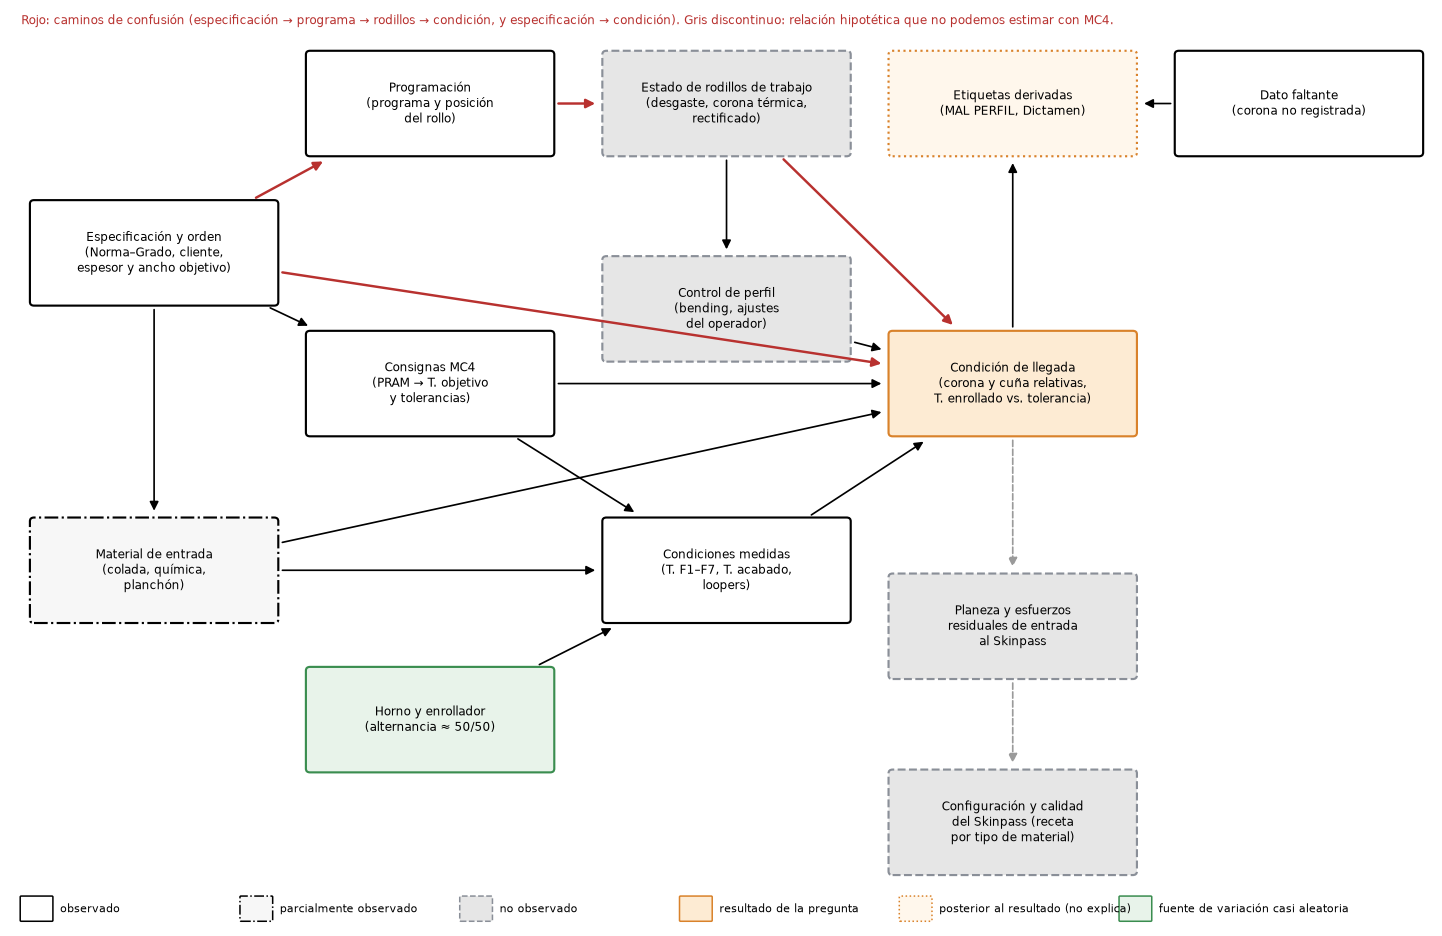

In [7]:
print(guardar(diagrama_causal(), "diagrama_causal"))

---
**Callejones sin salida y protocolo de depuración:** ver `docs/anexos/C_callejones_sin_salida.md`
y `src/depuracion.py`. **Documento de la entrega:** `docs/entrega1.md`.